In [2]:
# Librerías para manejo de datos
import numpy as np
import pandas as pd

# Librerías para procesamiento y visualización de imágenes
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para aprendizaje automático
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

# Librerías para manejo de archivos
import os
import glob
import random
!pip install kagglehub

In [3]:
import kagglehub
import os


path = kagglehub.dataset_download("steubk/wikiart")

print("Dataset descargado en:")
print(path)

Dataset descargado en:
C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1


In [4]:
# Mostrar la estructura principal del dataset
for root, dirs, files in os.walk(path):
    print(root)
    print("Número de archivos:", len(files))
    print()
    
    # Solo inspeccionamos los primeros niveles
    if root.count(os.sep) >= path.count(os.sep) + 2:
        dirs[:] = []

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1
Número de archivos: 2

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Abstract_Expressionism
Número de archivos: 2782

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Action_painting
Número de archivos: 98

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Analytical_Cubism
Número de archivos: 110

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Art_Nouveau_Modern
Número de archivos: 4334

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Baroque
Número de archivos: 4240

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Color_Field_Painting
Número de archivos: 1615

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Contemporary_Realism
Número de archivos: 481

C:\Users\julia\.cache\kagglehub\datasets\steubk\wikiart\versions\1\Cubism
Número de archivos: 2235

C:\Users\julia\.cache\kagglehub\datas

In [5]:
# Obtener los estilos disponibles en el dataset

styles_path = path

styles = [
    folder for folder in os.listdir(styles_path)
    if os.path.isdir(os.path.join(styles_path, folder))
]

print(f"Número de estilos encontrados: {len(styles)}")
print("\nEstilos disponibles:")

for i, style in enumerate(sorted(styles), 1):
    print(f"{i}. {style}")


Número de estilos encontrados: 27

Estilos disponibles:
1. Abstract_Expressionism
2. Action_painting
3. Analytical_Cubism
4. Art_Nouveau_Modern
5. Baroque
6. Color_Field_Painting
7. Contemporary_Realism
8. Cubism
9. Early_Renaissance
10. Expressionism
11. Fauvism
12. High_Renaissance
13. Impressionism
14. Mannerism_Late_Renaissance
15. Minimalism
16. Naive_Art_Primitivism
17. New_Realism
18. Northern_Renaissance
19. Pointillism
20. Pop_Art
21. Post_Impressionism
22. Realism
23. Rococo
24. Romanticism
25. Symbolism
26. Synthetic_Cubism
27. Ukiyo_e


In [6]:
#	Estilo	Por qué es interesante para nuestro objetivo
#1	Impressionism	Muchas transiciones y variaciones suaves de color
#2	Post_Impressionism	Colores intensos y contrastantes
#3	Cubism	Regiones y formas con colores diferenciados
#4	Expressionism	Uso frecuente de colores fuertes y contrastados
#5	Baroque	Contrastes marcados entre zonas claras y oscuras
#6	Fauvism	Colores muy saturados y poco realistas
#7	Pointillism	Muchos colores pequeños distribuidos por la imagen
#8	Minimalism	Distribuciones cromáticas más simples
# Estilos que vamos a explorar
selected_styles = [
    "Impressionism",
    "Post_Impressionism",
    "Cubism",
    "Expressionism",
    "Baroque",
    "Fauvism",
    "Pointillism",
    "Minimalism"
]

# Mostrar 5 archivos aleatorios de cada estilo
for style in selected_styles:
    
    style_path = os.path.join(path, style)
    
    files = [
        f for f in os.listdir(style_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    print(f"\n{style}: {len(files)} imágenes")
    
    samples = random.sample(files, min(5, len(files)))
    
    for file in samples:
        print("  ", file)


Impressionism: 13060 imágenes
   abraham-manievich_flowers-vase-on-a-hamper.jpg
   valentin-serov_portrait-of-princess-polina-shcherbatova-1911.jpg
   mary-cassatt_woman-and-child-seated-in-a-garden.jpg
   pierre-auguste-renoir_gladioli.jpg
   guy-rose_laguna-1.jpg

Post_Impressionism: 6450 imágenes
   stefan-popescu_still-life-with-gourd.jpg
   moise-kisling_female-portrait.jpg
   ferdinand-hodler_landscape-near-champery-1913.jpg
   christo-coetzee_still-life-with-fruit-bowl.jpg
   mily-possoz_l-arbre-de-no-l-i-1930.jpg

Cubism: 2235 imágenes
   pablo-picasso_jacqueline-with-flowers-1954.jpg
   pablo-picasso_guitar-bottle-and-fruit-bowl-1921.jpg
   carlos-merida_el-doble-1977.jpg
   marc-chagall_green-lovers-1915.jpg
   rufino-tamayo_woman-with-pineapple-1941.jpg

Expressionism: 6736 imágenes
   vasile-kazar_fiddlers-at-wedding-1968.jpg
   paul-klee_death-and-fire-1940(1).jpg
   jackson-pollock_landscape-with-steer-1937(2).jpg
   henri-matisse_still-life-with-aubergines-1911.jpg
   m

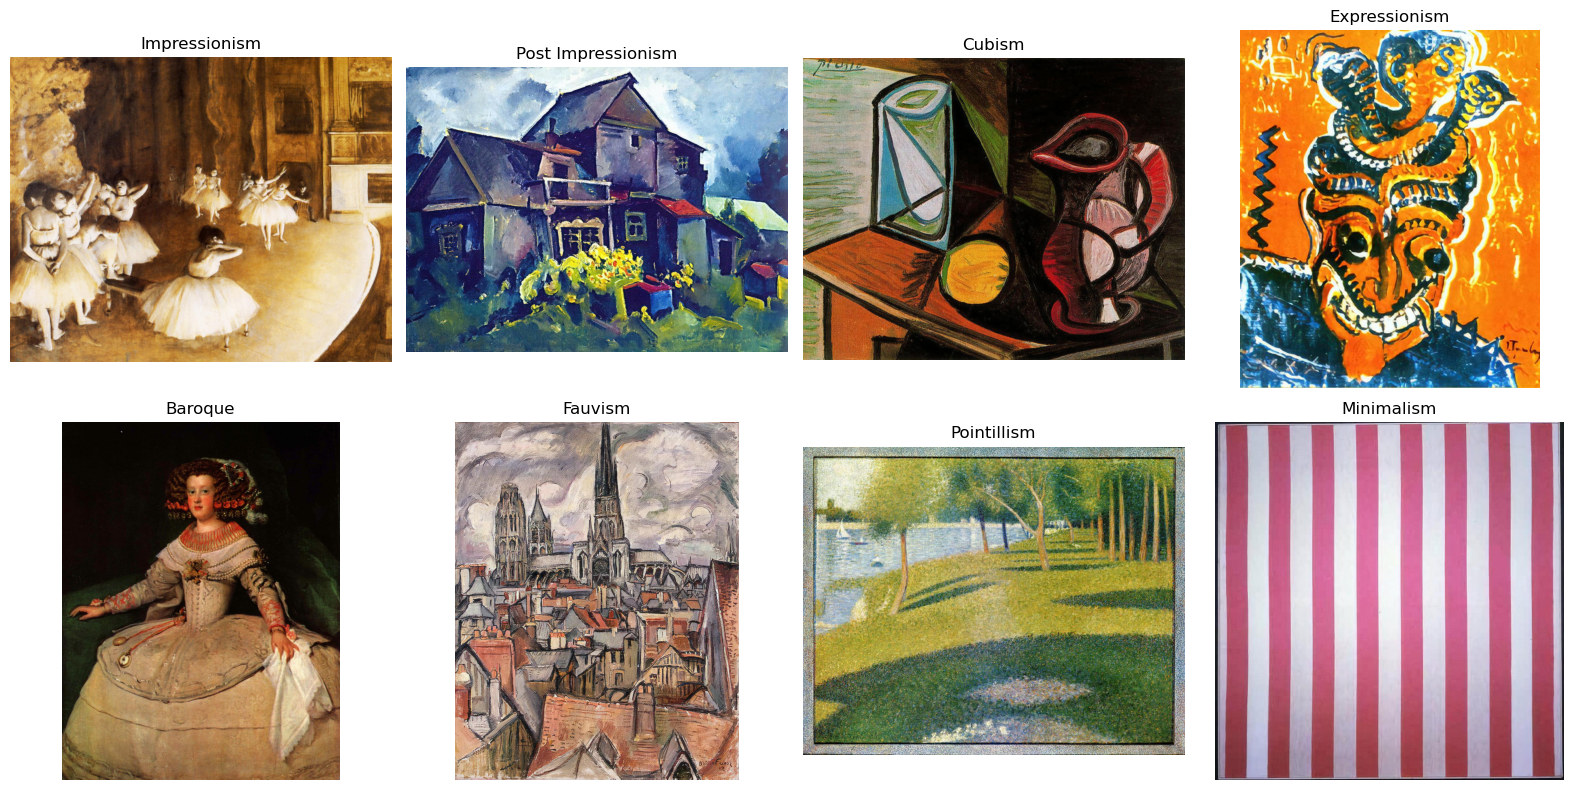

In [7]:
# Selección de las imágenes

#Para el desarrollo del método se seleccionaron ocho obras de arte
#pertenecientes a ocho estilos artísticos diferentes presentes en el
#conjunto de datos WikiArt.

#La selección busca proporcionar diversidad en las características
#visuales y cromáticas de las imágenes. De esta manera, el método podrá
#ser evaluado posteriormente sobre obras con diferentes distribuciones
#de color, desde imágenes con una cantidad reducida de tonalidades hasta
#obras con una mayor variedad cromática.

#Los estilos artísticos se utilizan únicamente como criterio para
#obtener una muestra diversa. El objetivo del proyecto no es clasificar
#las obras según su estilo, sino identificar y agrupar los colores
#dominantes presentes en cada imagen.
    
import matplotlib.pyplot as plt
from PIL import Image

selected_images = {
    "Impressionism": "edgar-degas_the-ballet-rehearsal-on-stage-1874.jpg",
    "Post_Impressionism": "aristarkh-lentulov_country-house-village-zyuzino.jpg",
    "Cubism": "pablo-picasso_glass-and-pitcher-1944.jpg",
    "Expressionism": "ion-tuculescu_african-mask-1939.jpg",
    "Baroque": "diego-velazquez_portrait-of-the-infanta-maria-teresa-future-queen-marie-therese-of-france-1653.jpg",
    "Fauvism": "othon-friesz_roofs-and-cathedral-in-rouen-1908.jpg",
    "Pointillism": "georges-seurat_la-grande-jatte-1884.jpg",
    "Minimalism": "daniel-buren_peinture-acrylique-blanche-sur-tissu-ray-blanc-et-rouge-1970.jpg"
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, (style, filename) in zip(axes.flat, selected_images.items()):

    image_path = os.path.join(path, style, filename)

    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(style.replace("_", " "))
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
### Obras seleccionadas

#| Estilo | Artista | Obra |
#|---|---|---|
#| Impressionism | Edgar Degas | *The Ballet Rehearsal on Stage* |
#| Post-Impressionism | Aristarkh Lentulov | *Country House, Village Zyuzino* |
#| Cubism | Pablo Picasso | *Glass and Pitcher* |
#| Expressionism | Ion Țuculescu | *African Mask* |
#| Baroque | Diego Velázquez | *Portrait of the Infanta Maria Teresa* |
#| Fauvism | Othon Friesz | *Roofs and Cathedral in Rouen* |
#| Pointillism | Georges Seurat | *La Grande Jatte* |
#| Minimalism | Daniel Buren | *Peinture acrylique blanche sur tissu rayé blanc et rouge* |

In [9]:
# 1. Redimensionamiento: Se estableció una dimensión máxima de 700 píxeles para reducir 
# el costo computacional del procesamiento, manteniendo al mismo tiempo una cantidad 
# suficiente de píxeles para conservar la distribución cromática de las obras. El 
# redimensionamiento mantiene la relación de aspecto original para evitar deformaciones.

for style, filename in selected_images.items():
    
    image_path = os.path.join(path, style, filename)
    image = Image.open(image_path)
    
    print(f"{style}: {image.size}")

Impressionism: (1729, 1382)
Post_Impressionism: (1851, 1382)
Cubism: (1746, 1382)
Expressionism: (1382, 1653)
Baroque: (1382, 1782)
Fauvism: (1382, 1742)
Pointillism: (1706, 1382)
Minimalism: (1382, 1419)


In [10]:
def preparar_imagen(image, max_size=700):
    """
    Redimensiona la imagen manteniendo su relación de aspecto
    y la convierte al espacio de color RGB.
    """
    
    image = image.copy()
    
    # Redimensionamiento manteniendo proporciones
    image.thumbnail((max_size, max_size))
    
    # Conversión a RGB
    image = image.convert("RGB")
    
    return image
for style, filename in selected_images.items():
    
    image_path = os.path.join(path, style, filename)
    image = Image.open(image_path)
    
    prepared_image = preparar_imagen(image)
    
    print(
        f"{style}: "
        f"{image.size} → {prepared_image.size} | "
        f"Modo: {prepared_image.mode}"
    )

Impressionism: (1729, 1382) → (700, 560) | Modo: RGB
Post_Impressionism: (1851, 1382) → (700, 523) | Modo: RGB
Cubism: (1746, 1382) → (700, 554) | Modo: RGB
Expressionism: (1382, 1653) → (585, 700) | Modo: RGB
Baroque: (1382, 1782) → (543, 700) | Modo: RGB
Fauvism: (1382, 1742) → (555, 700) | Modo: RGB
Pointillism: (1706, 1382) → (700, 567) | Modo: RGB
Minimalism: (1382, 1419) → (682, 700) | Modo: RGB


In [11]:
### Representación de las imágenes como datos RGB

#Una vez redimensionadas las imágenes, estas se representan en el espacio
#de color RGB. Cada píxel de una imagen está compuesto por tres valores
#numéricos correspondientes a los canales rojo (R), verde (G) y azul (B),
#con valores entre 0 y 255.

#Esta representación resulta adecuada para el objetivo del proyecto,
#debido a que el método de agrupación trabajará sobre los colores de los
#píxeles. De esta manera, cada píxel puede considerarse como una
#observación definida por tres características:

#- R: intensidad del canal rojo.
#- G: intensidad del canal verde.
#- B: intensidad del canal azul.

#Originalmente, una imagen se representa mediante una estructura
#tridimensional de dimensiones:

#(alto, ancho, 3)

#donde las dos primeras dimensiones corresponden a la posición espacial
#del píxel y la tercera contiene sus componentes RGB.

#Para aplicar posteriormente el algoritmo de agrupación, se reorganiza
#esta estructura en una matriz bidimensional de dimensiones:

#(número de píxeles, 3)

#En esta matriz, cada fila representa un píxel y cada columna representa
#uno de los canales RGB. Esta transformación permite utilizar los píxeles
#como observaciones independientes dentro del algoritmo de clustering,
#manteniendo la información necesaria para determinar la similitud entre
#colores.

style = "Pointillism"
filename = selected_images[style]

image_path = os.path.join(path, style, filename)

image = Image.open(image_path)

prepared_image = preparar_imagen(image)

pixels = np.array(prepared_image)
pixels = pixels.reshape(-1, 3)

print("Dimensiones de la imagen:", prepared_image.size)
print("Forma antes de reorganizar:", np.array(prepared_image).shape)
print("Forma de la matriz de píxeles:", pixels.shape)
print("\nPrimeros 10 píxeles:")
print(pixels[:10])

Dimensiones de la imagen: (700, 567)
Forma antes de reorganizar: (567, 700, 3)
Forma de la matriz de píxeles: (396900, 3)

Primeros 10 píxeles:
[[ 66  65  72]
 [ 98  97  97]
 [ 93  94  84]
 [ 88  96  83]
 [ 55  73  63]
 [ 58  88  84]
 [ 74  94  96]
 [ 90  94  97]
 [117 126 127]
 [ 96 109 109]]


In [ ]:
# **Problema encontrado con la selección de K**
#
# Inicialmente se utilizó K-Means para realizar el agrupamiento de los
# colores. Este algoritmo requiere establecer previamente el número de
# grupos K, por lo que fue necesario evaluar diferentes valores de K para
# determinar cuál representaba mejor la distribución cromática de cada
# imagen.
#
# Para realizar esta selección inicialmente se consideró el Silhouette Score
# como criterio principal. Sin embargo, durante las pruebas realizadas se
# identificó una inconsistencia entre el valor de K que obtenía el mejor
# resultado en esta métrica y la cantidad de colores necesaria para
# representar adecuadamente la diversidad cromática de una imagen.
#
# En particular, se observó que un K reducido podía obtener un mejor
# Silhouette Score, aunque la visualización de las paletas generadas con
# valores superiores de K mostraba tonalidades adicionales que resultaban
# relevantes para representar la obra.
#
# Esto evidenció que la selección de K no podía depender exclusivamente de
# una única métrica de agrupamiento, ya que una agrupación matemáticamente
# favorable no necesariamente producía la representación cromática más
# informativa para el objetivo del proyecto.
#
# Para analizar este comportamiento se complementó inicialmente la
# evaluación mediante tres criterios: Silhouette Score, índice
# Davies-Bouldin y método del codo. Cada uno permite evaluar la agrupación
# desde una perspectiva diferente.
#
#
# **Silhouette Score**
#
# El Silhouette Score evalúa simultáneamente la cohesión de los elementos
# dentro de cada grupo y la separación entre grupos diferentes. Sus valores
# se encuentran entre -1 y 1, donde valores más altos indican una mejor
# estructura de agrupación. En consecuencia, para este criterio se
# considera que un valor mayor es mejor.
#
#
# **Índice Davies-Bouldin**
#
# El índice Davies-Bouldin evalúa la similitud entre los diferentes grupos,
# considerando tanto la dispersión interna de cada grupo como la separación
# entre ellos. Valores más bajos indican grupos más compactos y mejor
# separados. Por lo tanto, para este criterio se considera que un valor
# menor es mejor.
#
#
# **Método del codo**
#
# El método del codo analiza la evolución de la inercia al incrementar el
# número de grupos. La inercia representa la suma de las distancias
# cuadráticas entre cada píxel y el centroide de su grupo.
#
# Al aumentar K, la inercia disminuye porque los grupos se vuelven más
# específicos. Sin embargo, llega un punto en el que aumentar nuevamente
# el número de grupos produce una mejora cada vez menor. Este punto,
# conocido como "codo", permite identificar un equilibrio entre la
# reducción del error de agrupamiento y la cantidad de grupos utilizados.
#
#
# **Cambio de K-Means a Mean Shift**
#
# A pesar de evaluar diferentes criterios para la selección de K, se
# identificó que establecer previamente un número de grupos continuaba
# siendo una limitación para el objetivo del proyecto.
#
# Las pinturas analizadas presentan distribuciones cromáticas diferentes,
# por lo que no resulta adecuado asumir que todas deben representarse con
# la misma cantidad de clusters.
#
# Debido a esto, se decidió utilizar **Mean Shift** como método de
# agrupamiento inicial. A diferencia de K-Means, Mean Shift no requiere
# especificar previamente el número de clusters, sino que identifica
# automáticamente las agrupaciones presentes en la distribución de los
# datos.
#
# De esta manera, Mean Shift permite adaptar la cantidad inicial de
# candidatos cromáticos a las características de cada imagen. Estos
# clusters no representan directamente la paleta final, sino que constituyen
# un conjunto inicial de candidatos que posteriormente son depurados
# mediante los filtros cromáticos y las reglas de selección.


from sklearn.cluster import KMeans
import time

sample_sizes = [10000, 25000, 50000, 100000]

for n_samples in sample_sizes:
    
    indices = np.random.choice(
        len(pixels),
        size=n_samples,
        replace=False
    )
    
    sample_pixels = pixels[indices]
    
    inicio = time.time()
    
    modelo = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )
    
    modelo.fit(sample_pixels)
    
    tiempo = time.time() - inicio
    
    print(
        f"{n_samples:,} píxeles → "
        f"{tiempo:.2f} segundos"
    )

10,000 píxeles → 1.95 segundos
25,000 píxeles → 0.13 segundos
50,000 píxeles → 0.26 segundos
100,000 píxeles → 0.61 segundos


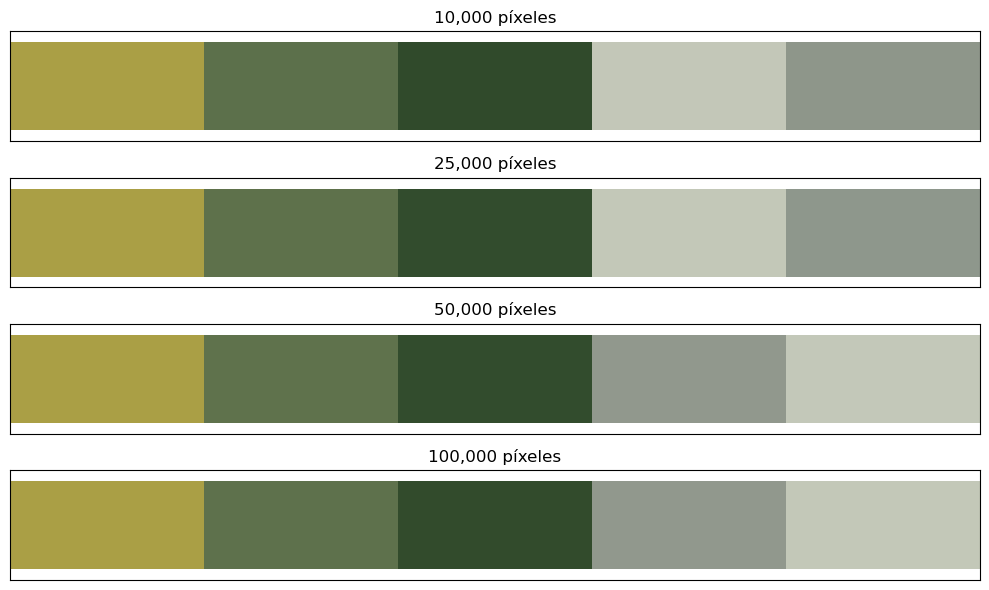

In [13]:
sample_sizes = [10000, 25000, 50000, 100000]

fig, axes = plt.subplots(4, 1, figsize=(10, 6))

for ax, n_samples in zip(axes, sample_sizes):

    # Seleccionar píxeles aleatoriamente
    indices = np.random.choice(
        len(pixels),
        size=n_samples,
        replace=False
    )

    sample_pixels = pixels[indices]

    # K-Means provisional
    modelo = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    modelo.fit(sample_pixels)

    colores = modelo.cluster_centers_.astype(int)

    # Ordenar colores por cantidad de píxeles
    counts = np.bincount(modelo.labels_)
    orden = np.argsort(counts)[::-1]

    colores = colores[orden]

    # Dibujar paleta
    for i, color in enumerate(colores):
        ax.barh(
            0,
            1,
            left=i,
            color=color / 255
        )

    ax.set_xlim(0, 5)
    ax.set_ylim(-0.5, 0.5)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_title(f"{n_samples:,} píxeles")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PIPELINE FINAL DE SELECCIÓN DE PALETAS
# ============================================================

# Para obtener una paleta de colores representativa de cada pintura se
# diseñó un pipeline compuesto por varias etapas de agrupamiento, filtrado
# y selección. El objetivo no es únicamente identificar colores diferentes,
# sino obtener una cantidad de colores que represente adecuadamente la
# diversidad cromática de la obra sin generar paletas excesivamente grandes.
#
# El procedimiento se divide en las siguientes etapas:
#
# 1. Muestreo de píxeles
# 2. Agrupamiento mediante Mean Shift
# 3. Filtrado mediante distancia cromática ΔE
# 4. Agrupación por familias cromáticas mediante Hue y C*
# 5. Selección mediante reglas de representatividad
# 6. Rescate de colores cromáticamente relevantes


# **Pipeline final**
#
# Con todas las etapas integradas, el procedimiento queda definido de la
# siguiente manera:
#
# Imagen
#     ↓
# Muestreo de 5.000 píxeles
#     ↓
# Mean Shift
# quantile = 0.05
#     ↓
# Clusters candidatos
#     ↓
# Filtro ΔE
# ΔE ≥ 20
#     ↓
# Filtro cromático
# Hue = 25° + C*
#     ↓
# Familias cromáticas
#     ↓
# Regla del 10 %
#     ↓
# Regla acumulativa
#     ↓
# Paleta seleccionada normalmente
#     ↓
# Rescate cromático
# ΔE ≥ 30 respecto a las gamas dominantes
# Sin limite de colores rescatados
#     ↓
# Paleta final

from sklearn.cluster import MeanShift, estimate_bandwidth
from skimage.color import rgb2lab
import pandas as pd
import numpy as np
import os
from PIL import Image
import colorsys


# ============================================================
# PARÁMETROS
# ============================================================

QUANTILE = 0.05

# Primer filtro: distancia cromática
DELTA_E_MIN = 20

# Segundo filtro: familias cromáticas
HUE_UMBRAL = 25
C_MIN = 15

# Reglas de representatividad
PORCENTAJE_MIN = 0.10

# Regla de rescate
DELTA_E_RESCATE = 30

# Máximo de colores que pueden ser rescatados
MAX_RESCATADOS = 1


# ============================================================
# FUNCIONES AUXILIARES
# ============================================================

def calcular_delta_e(color1_lab, color2_lab):
    """
    Distancia euclídea en el espacio CIELAB.
    """
    return np.linalg.norm(
        np.array(color1_lab) - np.array(color2_lab)
    )


def rgb_a_lab(color_rgb):
    """
    Convierte RGB [0-255] a CIELAB.
    """
    rgb = np.array(color_rgb, dtype=float) / 255.0

    lab = rgb2lab(
        rgb.reshape(1, 1, 3)
    )[0, 0]

    return lab


def calcular_hue_y_c(rgb):
    """
    Calcula Hue y C* a partir de RGB.
    """
    rgb_norm = np.array(rgb, dtype=float) / 255.0

    lab = rgb2lab(
        rgb_norm.reshape(1, 1, 3)
    )[0, 0]

    L, a, b = lab

    c = np.sqrt(a**2 + b**2)

    hue = np.degrees(
        np.arctan2(b, a)
    ) % 360

    return hue, c, lab


def diferencia_hue(h1, h2):
    """
    Calcula la distancia angular mínima entre dos valores de Hue.
    """
    diferencia = abs(h1 - h2)

    return min(
        diferencia,
        360 - diferencia
    )


# ============================================================
# PIPELINE
# ============================================================

resultados_finales = []
detalles_finales = []

for style, filename in selected_images.items():

    print("=" * 70)
    print(f"Evaluando: {style}")
    print("=" * 70)

    # --------------------------------------------------------
    # 1. CARGAR IMAGEN
    # --------------------------------------------------------

    image_path = os.path.join(
        path,
        style,
        filename
    )

    image = Image.open(image_path)

    prepared_image = preparar_imagen(image)

    pixels = np.array(
        prepared_image
    ).reshape(-1, 3)

# **Muestreo de 5.000 píxeles**
#
# Para realizar el agrupamiento se seleccionó una muestra aleatoria de
# 5.000 píxeles por imagen. Este tamaño permite reducir considerablemente
# el costo computacional del procesamiento, manteniendo una cantidad
# suficiente de información para identificar las principales agrupaciones
# cromáticas de la pintura.
#
# Se utiliza además una semilla fija para garantizar que el proceso sea
# reproducible.
    # --------------------------------------------------------
    # 2. MUESTREO
    # --------------------------------------------------------

    np.random.seed(42)

    n_samples = min(
        5000,
        len(pixels)
    )

    indices = np.random.choice(
        len(pixels),
        size=n_samples,
        replace=False
    )

    sample_pixels = pixels[
        indices
    ]

# **Mean Shift**
#
# Se seleccionó Mean Shift como método inicial de agrupamiento porque
# permite identificar automáticamente grupos de colores sin establecer
# previamente el número de clusters K. Esto resulta conveniente para el
# proyecto debido a que las pinturas pertenecientes a diferentes estilos
# pueden presentar niveles de diversidad cromática muy diferentes.
#
# Durante las pruebas se observó precisamente este comportamiento. Mean
# Shift encontró cantidades diferentes de clusters para cada pintura,
# dependiendo de la distribución de sus colores. Por ejemplo, algunas
# imágenes produjeron pocos clusters, mientras que otras generaron más de
# veinte.
#
# Por esta razón, Mean Shift no se utiliza para determinar directamente la
# cantidad final de colores de la paleta. Su función es generar un conjunto
# inicial de candidatos cromáticos que posteriormente serán filtrados y
# organizados.




# **Quantile = 0.05**
#
# En Mean Shift, el parámetro quantile influye en la estimación del
# bandwidth y, por tanto, en la cantidad y sensibilidad de los grupos
# encontrados.
#
# Durante las pruebas se observó que valores mayores podían producir una
# cantidad demasiado reducida de clusters. Debido a que Mean Shift se
# utiliza como una etapa de generación de candidatos, se estableció un
# quantile de 0.05 para aumentar la sensibilidad y obtener una cantidad
# suficiente de candidatos cromáticos.
#
# Los candidatos adicionales no representan necesariamente colores finales,
# ya que serán depurados mediante las etapas posteriores del pipeline.
    # --------------------------------------------------------
    # 3. MEAN SHIFT
    # --------------------------------------------------------

    bandwidth = estimate_bandwidth(
        sample_pixels,
        quantile=QUANTILE,
        n_samples=n_samples
    )

    modelo_ms = MeanShift(
        bandwidth=bandwidth,
        bin_seeding=True
    )

    etiquetas = modelo_ms.fit_predict(
        sample_pixels
    )

    clusters, counts = np.unique(
        etiquetas,
        return_counts=True
    )

    porcentajes = (
        counts /
        len(etiquetas)
    ) * 100

    orden = np.argsort(
        porcentajes
    )[::-1]


    # --------------------------------------------------------
    # 4. OBTENER CANDIDATOS
    # --------------------------------------------------------

    candidatos = []

    for posicion in orden:

        cluster = clusters[posicion]

        porcentaje = porcentajes[posicion]

        color = (
            modelo_ms
            .cluster_centers_[cluster]
            .astype(float)
        )

        hue, c, lab = calcular_hue_y_c(
            color
        )

        candidatos.append({
            "cluster": cluster,
            "porcentaje": porcentaje,
            "R": color[0],
            "G": color[1],
            "B": color[2],
            "Hue": hue,
            "C": c,
            "L": lab
        })



# **Filtro mediante distancia cromática ΔE**
#
# Después de obtener los clusters mediante Mean Shift se aplica un primer
# filtro basado en la distancia cromática ΔE.
#
# Este filtro tiene como objetivo eliminar colores demasiado similares
# entre sí. Mean Shift puede producir diferentes clusters cuyas tonalidades
# sean muy cercanas, por lo que conservar todos estos grupos provocaría
# redundancia dentro de la paleta.
#
# Se estableció un umbral de:
#
# ΔE ≥ 20
#
# Un nuevo color solamente se conserva cuando presenta una diferencia
# cromática suficiente respecto a los colores que ya fueron aceptados.
#
# De esta manera, el filtro reduce la redundancia sin eliminar
# necesariamente colores que representen tonalidades cromáticamente
# diferenciadas.
    # --------------------------------------------------------
    # 5. FILTRO ΔE
    # --------------------------------------------------------

    candidatos_delta_e = []

    for candidato in candidatos:

        if len(candidatos_delta_e) == 0:

            candidatos_delta_e.append(
                candidato
            )

            continue

        aceptar = True

        for aceptado in candidatos_delta_e:

            delta_e = calcular_delta_e(
                candidato["L"],
                aceptado["L"]
            )

            if delta_e < DELTA_E_MIN:

                aceptar = False
                break

        if aceptar:

            candidatos_delta_e.append(
                candidato
            )


# **Filtro de familias cromáticas mediante Hue y C***
#
# Aunque el filtro ΔE elimina colores muy similares, todavía puede ocurrir
# que diferentes tonalidades pertenezcan a una misma gama cromática.
#
# Por ejemplo, diferentes tonos de naranja pueden encontrarse separados
# suficientemente en el espacio de color para superar el filtro ΔE, pero
# seguir perteneciendo conceptualmente a una misma familia cromática.
#
# Por esta razón se incorporó el análisis del Hue, que representa la
# posición del color dentro del círculo cromático.
#
# Se estableció un umbral de:
#
# ΔHue = 25°
#
# Los colores cromáticos cuya diferencia de Hue se encuentra dentro de este
# intervalo se consideran pertenecientes a una misma familia cromática.
#
# También se utiliza la cromaticidad C* para determinar si un color posee
# suficiente saturación cromática como para que su Hue sea representativo.
# Se estableció:
#
# C* < 15 → color neutro
#
# Esto evita utilizar el Hue como criterio principal en colores con muy baja
# cromaticidad, como blancos, grises y negros.
    # --------------------------------------------------------
    # 6. FILTRO HUE + C*
    # --------------------------------------------------------

    familias = []

    for candidato in candidatos_delta_e:

        # Los colores neutros no se agrupan mediante Hue
        if candidato["C"] < C_MIN:

            candidato["tipo"] = "Neutro"

            familias.append(
                candidato
            )

            continue

        candidato["tipo"] = "Cromático"

        pertenece = False

        for familia in familias:

            if familia["tipo"] != "Cromático":
                continue

            diferencia = diferencia_hue(
                candidato["Hue"],
                familia["Hue"]
            )

            if diferencia <= HUE_UMBRAL:

                pertenece = True
                break

        if not pertenece:

            familias.append(
                candidato
            )


    # --------------------------------------------------------
    # 7. ORDENAR FAMILIAS POR REPRESENTATIVIDAD
    # --------------------------------------------------------

    familias = sorted(
        familias,
        key=lambda x: x["porcentaje"],
        reverse=True
    )



# **Reglas de representatividad**
#
# Después de aplicar los filtros cromáticos se obtiene un conjunto reducido
# de familias de colores. Sin embargo, todavía es necesario determinar
# cuáles de estas familias deben formar parte de la paleta final.
#
# Para ello se establecieron dos reglas basadas en la representatividad de
# los colores dentro de la imagen.
#
#
# **Regla del 10 %**
#
# Se compara el porcentaje de cada color con el porcentaje del color
# inmediatamente anterior en la distribución ordenada de mayor a menor.
#
# Si el siguiente color representa menos del 10 % del porcentaje del color
# anterior, se detiene la incorporación de nuevos colores.
#
# Esta condición evita que una sucesión de colores cada vez menos
# representativos genere una paleta excesivamente grande.
#
#
# **Regla acumulativa**
#
# Además de evaluar cada color individualmente, se controla la suma de los
# colores secundarios incorporados.
#
# Si la suma acumulada de los colores secundarios alcanza el porcentaje del
# segundo color más dominante, se detiene la incorporación de nuevos
# colores.
#
# Esta regla evita que numerosos colores individualmente pequeños puedan
# acumularse y producir una paleta excesivamente extensa.
    # --------------------------------------------------------
    # 8. REGLAS DE REPRESENTATIVIDAD
    # --------------------------------------------------------

    seleccionados = []

    porcentaje_acumulado_secundarios = 0

    segundo_porcentaje = None

    for candidato in familias:

        porcentaje = candidato[
            "porcentaje"
        ]

        # Primer color
        if len(seleccionados) == 0:

            seleccionados.append(
                candidato
            )

            continue

        # Segundo color
        if len(seleccionados) == 1:

            seleccionados.append(
                candidato
            )

            segundo_porcentaje = porcentaje

            continue

        anterior = seleccionados[-1][
            "porcentaje"
        ]

        # Regla del 10 %
        if porcentaje < (
            anterior * PORCENTAJE_MIN
        ):
            break

        # Regla acumulativa
        if (
            porcentaje_acumulado_secundarios
            + porcentaje
        ) >= segundo_porcentaje:

            break

        seleccionados.append(
            candidato
        )

        porcentaje_acumulado_secundarios += (
            porcentaje
        )


# **Problema de los colores minoritarios**
#
# Durante las pruebas se observó que las reglas basadas únicamente en la
# frecuencia de los colores podían descartar colores que, aunque ocuparan
# una proporción muy pequeña de la imagen, presentaban una diferencia
# cromática importante respecto a las gamas dominantes.
#
# Este comportamiento fue especialmente evidente en Baroque.
#
# En esta imagen, después de los filtros cromáticos se identificaron
# familias con porcentajes aproximados de:
#
# C1 → 41.38 %
# C2 → 16.76 %
# C3 → 0.14 %
# C4 → 0.04 %
#
# Las reglas de representatividad descartaban los últimos colores debido a
# su baja frecuencia. Sin embargo, el tercer color presentaba una distancia
# cromática de aproximadamente ΔE = 42.16 respecto a las gamas dominantes.
#
# Esto mostró que la frecuencia espacial no siempre es suficiente para
# determinar la relevancia de un color dentro de una obra artística.





# **Rescate cromático**
#
# Para solucionar este problema se incorporó una etapa adicional de rescate
# cromático.
#
# Inicialmente se estableció un límite de un solo color rescatado por
# imagen. Sin embargo, al analizar los resultados se observó que algunas
# pinturas contenían más de un color minoritario que cumplía simultáneamente
# con la condición de rescate.
#
# Estos colores habían sido descartados por las reglas de representatividad
# debido a su baja frecuencia, pero presentaban una distancia cromática
# suficientemente elevada respecto a las dos gamas dominantes.
#
# Por esta razón, se consideró que limitar artificialmente el número de
# colores rescatados podía provocar nuevamente la pérdida de información
# cromática relevante, que era precisamente el problema que se buscaba
# solucionar con esta etapa.
#
# En consecuencia, se eliminó el límite máximo de colores rescatados.
# Todos los candidatos que cumplan la condición:
#
# ΔE ≥ 30 respecto a las dos gamas dominantes
#
# son incorporados a la paleta final.
#
# De esta manera, el rescate no depende de una cantidad fija de colores,
# sino de una condición cromática objetiva. Un color solamente puede ser
# incorporado mediante esta etapa cuando demuestra una diferencia
# suficientemente elevada respecto a las gamas principales de la obra.
#
# Esto permite que el tamaño de la paleta se adapte a la complejidad
# cromática de cada imagen. Una pintura que no contenga colores minoritarios
# suficientemente diferenciados no incorporará colores adicionales,
# mientras que una pintura que presente varias gamas cromáticamente
# diferenciadas podrá conservarlas.
#
# Por tanto, el mecanismo de rescate funciona como una excepción a las
# reglas de representatividad: estas últimas priorizan los colores según
# su presencia en la imagen, mientras que el rescate permite recuperar
# colores de baja frecuencia cuando su diferenciación cromática justifica
# su inclusión.
    # --------------------------------------------------------
    # 9. RESCATE CROMÁTICO
    # --------------------------------------------------------

    # Los dos colores principales funcionan como referencia
    # para evaluar si un color minoritario es suficientemente
    # diferente de las gamas dominantes.

    dominantes = seleccionados[:2]

    candidatos_rescatables = []

    for candidato in familias:

        # Ya seleccionado normalmente
        if candidato in seleccionados:
            continue

        # Solo evaluar colores cromáticos
        if candidato["tipo"] != "Cromático":
            continue

        # Calcular ΔE contra los colores dominantes
        deltas = []

        for dominante in dominantes:

            delta = calcular_delta_e(
                candidato["L"],
                dominante["L"]
            )

            deltas.append(delta)

        # El candidato debe estar suficientemente alejado
        # de ambas gamas dominantes.
        if all(
            delta >= DELTA_E_RESCATE
            for delta in deltas
        ):

            candidato_rescatable = candidato.copy()

            candidato_rescatable[
                "delta_e_dominantes"
            ] = min(deltas)

            candidatos_rescatables.append(
                candidato_rescatable
            )


    # --------------------------------------------------------
    # SELECCIONAR TODOS LOS COLORES RESCATABLES
    # --------------------------------------------------------

    # Ordenar los candidatos rescatables desde el que presenta
    # mayor distancia cromática hasta el menor.

    candidatos_rescatables = sorted(
        candidatos_rescatables,
        key=lambda x: x["delta_e_dominantes"],
        reverse=True
    )

    # Incorporar todos los candidatos que cumplen
    # la condición de rescate cromático.

    rescates = candidatos_rescatables.copy()

    # Marcar como rescatados.

    for candidato in rescates:

        candidato[
            "seleccion"
        ] = "Rescatado"
    # --------------------------------------------------------
    # 10. PALETA FINAL
    # --------------------------------------------------------

    for candidato in seleccionados:

        candidato_final = candidato.copy()

        candidato_final[
            "seleccion"
        ] = "Normal"

        detalles_finales.append({
            "Estilo": style,
            "Cluster": candidato_final["cluster"],
            "Porcentaje": candidato_final["porcentaje"],
            "R": candidato_final["R"],
            "G": candidato_final["G"],
            "B": candidato_final["B"],
            "Hue": candidato_final["Hue"],
            "C*": candidato_final["C"],
            "Tipo": candidato_final["tipo"],
            "Selección": "Normal"
        })


    for candidato in rescates:

        detalles_finales.append({
            "Estilo": style,
            "Cluster": candidato["cluster"],
            "Porcentaje": candidato["porcentaje"],
            "R": candidato["R"],
            "G": candidato["G"],
            "B": candidato["B"],
            "Hue": candidato["Hue"],
            "C*": candidato["C"],
            "Tipo": candidato["tipo"],
            "Selección": "Rescatado"
        })


    # --------------------------------------------------------
    # RESULTADOS
    # --------------------------------------------------------

    k_normal = len(seleccionados)

    # Cantidad total de candidatos que cumplen
    # la condición de rescate.
    k_rescatables = len(
        candidatos_rescatables
    )

    # Cantidad que efectivamente se incorpora
    # a la paleta final.
    k_rescatados = len(
        rescates
    )

    k_final = (
        k_normal +
        k_rescatados
    )

    resultados_finales.append({
        "Estilo": style,
        "Clusters Mean Shift": len(candidatos),
        "Después ΔE": len(candidatos_delta_e),
        "Después Hue": len(familias),
        "K normal": k_normal,
        "Candidatos rescatables": k_rescatables,
        "Colores rescatados": k_rescatados,
        "K final": k_final,
        "Bandwidth": bandwidth
    })


# ============================================================
# RESULTADOS
# ============================================================

df_resultados_finales = pd.DataFrame(
    resultados_finales
)

df_paletas_finales = pd.DataFrame(
    detalles_finales
)


print("\n")
print("=" * 70)
print("RESULTADOS FINALES")
print("=" * 70)

display(
    df_resultados_finales
)


print("\n")
print("=" * 70)
print("PALETAS FINALES")
print("=" * 70)

display(
    df_paletas_finales
)

# **Resultado**
#
# El pipeline permite que la cantidad final de colores se adapte a las
# características cromáticas de cada pintura, en lugar de imponer un mismo
# número de colores para todas las obras.
#
# Los resultados obtenidos fueron:
#
# Impressionism       → K = 3
# Post-Impressionism  → K = 6
# Cubism              → K = 4
# Expressionism       → K = 4
# Baroque             → K = 3
# Fauvism             → K = 2
# Pointillism         → K = 3
# Minimalism          → K = 2
#
# De esta manera, el procedimiento considera tanto la representatividad
# espacial de los colores como su diferenciación cromática, permitiendo
# obtener paletas compactas pero suficientemente informativas para las
# diferentes obras analizadas.

Evaluando: Impressionism
Evaluando: Post_Impressionism
Evaluando: Cubism
Evaluando: Expressionism
Evaluando: Baroque
Evaluando: Fauvism
Evaluando: Pointillism
Evaluando: Minimalism


RESULTADOS FINALES


,Estilo,Clusters Mean Shift,Después ΔE,Después Hue,K normal,Candidatos rescatables,Colores rescatados,K final,Bandwidth
0,Impressionism,8,5,4,3,0,0,3,18.743679
1,Post_Impressionism,22,13,7,4,3,3,7,29.620958
2,Cubism,20,13,7,3,2,2,5,23.858542
3,Expressionism,19,10,6,6,0,0,6,30.933146
4,Baroque,24,7,4,2,2,2,4,15.399964
5,Fauvism,8,4,3,3,0,0,3,20.141987
6,Pointillism,6,4,4,4,0,0,4,26.199123
7,Minimalism,13,6,4,2,0,0,2,16.159807




PALETAS FINALES


,Estilo,Cluster,Porcentaje,R,G,B,Hue,C*,Tipo,Selección
0,Impressionism,0,36.98,79.191877,46.528011,22.547619,59.956379,24.706325,Cromático,Normal
1,Impressionism,1,19.50,238.696312,224.954447,202.210412,85.554339,12.856711,Neutro,Normal
2,Impressionism,6,10.70,221.005780,187.780347,120.190751,85.415689,38.646685,Cromático,Normal
3,Post_Impressionism,0,40.30,26.514312,30.009234,79.513389,297.381713,34.935205,Cromático,Normal
4,Post_Impressionism,3,17.76,111.161184,119.845395,144.648026,279.707854,14.726739,Neutro,Normal
5,Post_Impressionism,1,14.08,178.047059,206.682353,224.837647,244.955559,13.415997,Neutro,Normal
6,Post_Impressionism,5,3.40,113.925000,134.225000,43.250000,115.043004,49.338125,Cromático,Normal
7,Post_Impressionism,21,0.16,133.500000,89.000000,11.500000,75.343940,48.151136,Cromático,Rescatado
8,Post_Impressionism,13,0.54,190.956522,64.043478,73.086957,24.300808,56.271117,Cromático,Rescatado
9,Post_Impressionism,16,1.32,146.900000,52.700000,89.100000,359.132738,43.057093,Cromático,Rescatado


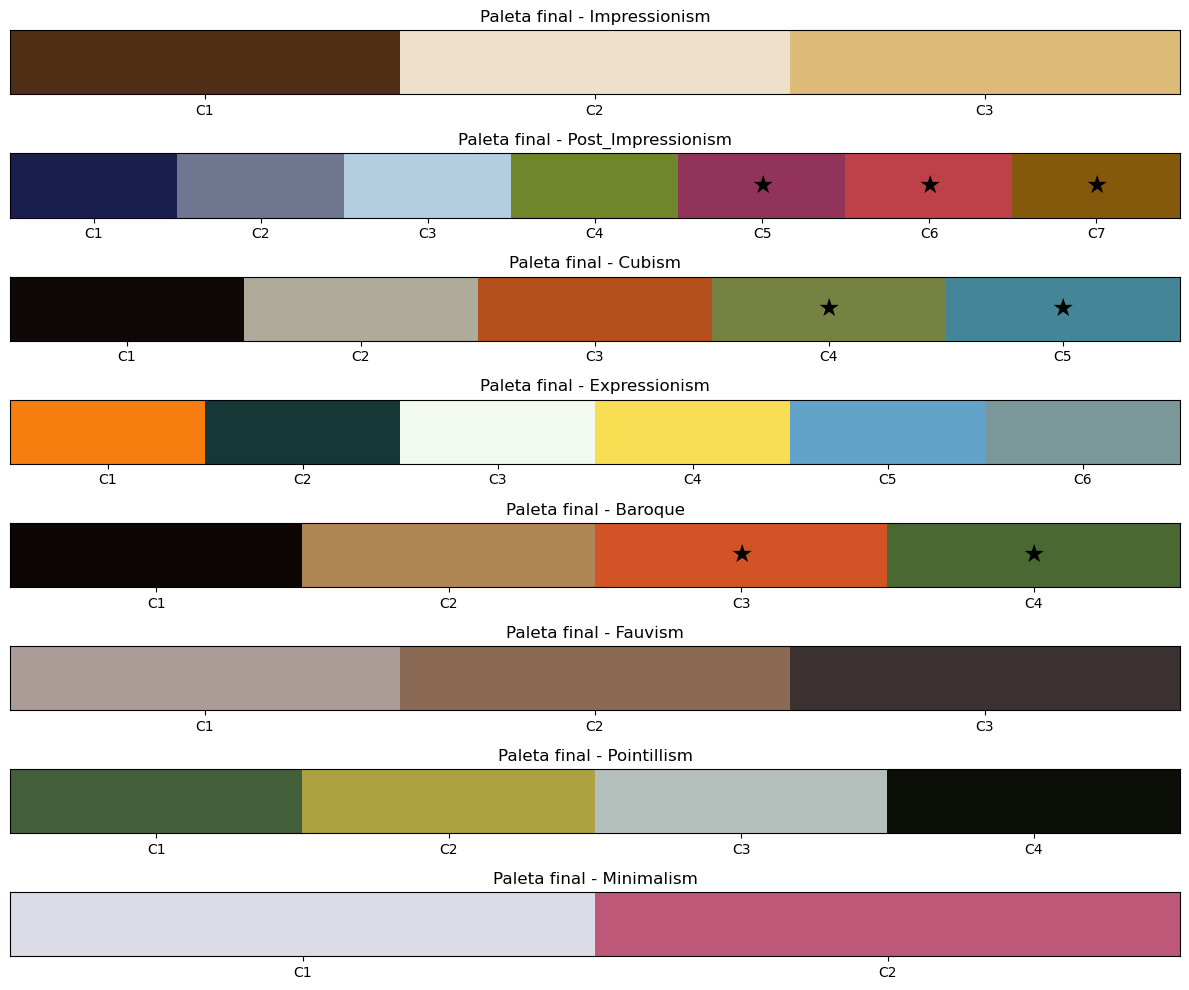

In [60]:
# =========================================================
# VISUALIZACIÓN DE LAS PALETAS FINALES
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

estilos = df_paletas_finales["Estilo"].unique()

fig, axes = plt.subplots(
    len(estilos),
    1,
    figsize=(12, 10)
)

# Si solo hubiera un estilo
if len(estilos) == 1:
    axes = [axes]

for ax, style in zip(axes, estilos):

    datos = df_paletas_finales[
        df_paletas_finales["Estilo"] == style
    ].copy()

    # Ordenar por porcentaje de mayor a menor
    datos = datos.sort_values(
        "Porcentaje",
        ascending=False
    )

    # Convertir RGB de 0-255 a 0-1
    colores = datos[
        ["R", "G", "B"]
    ].values / 255.0

    # Crear la paleta
    ax.imshow(
        [colores],
        aspect="auto"
    )

    # Eje X
    ax.set_xticks(
        np.arange(len(datos))
    )

    ax.set_xticklabels(
        [
            f"C{i+1}"
            for i in range(len(datos))
        ]
    )

    ax.set_yticks([])

    ax.set_title(
        f"Paleta final - {style}"
    )

    # Marcar colores rescatados
    for i, (_, fila) in enumerate(
        datos.iterrows()
    ):

        if fila["Selección"] == "Rescatado":

            ax.text(
                i,
                0,
                "★",
                ha="center",
                va="center",
                fontsize=18,
                color="black"
            )

plt.tight_layout()
plt.show()

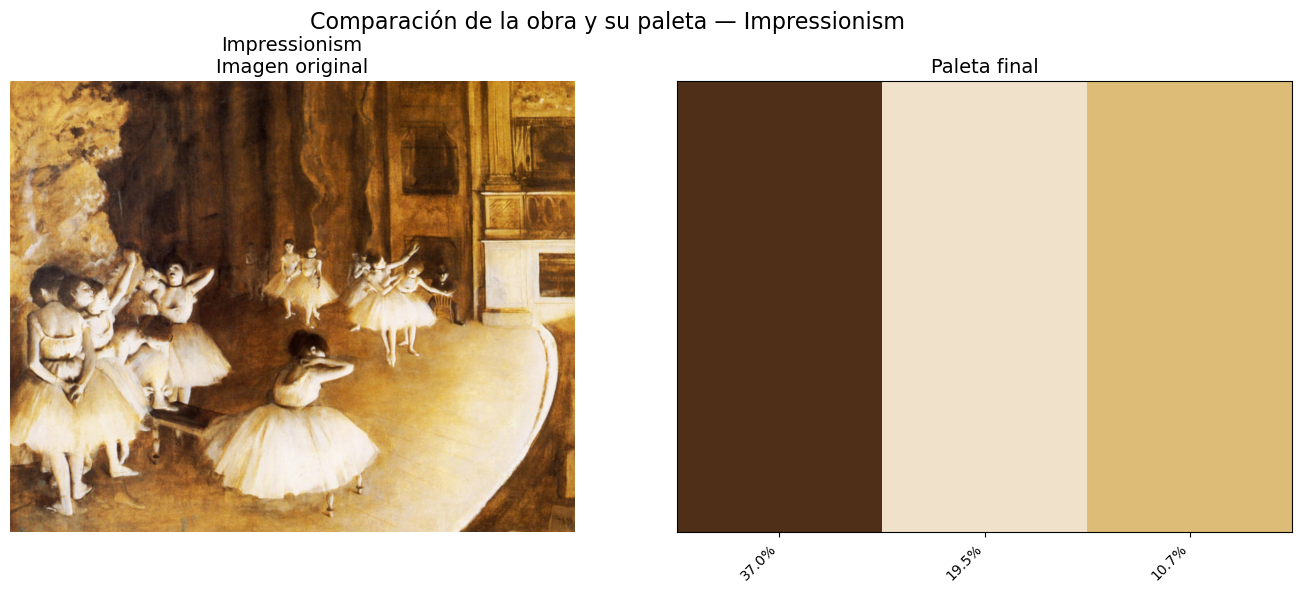

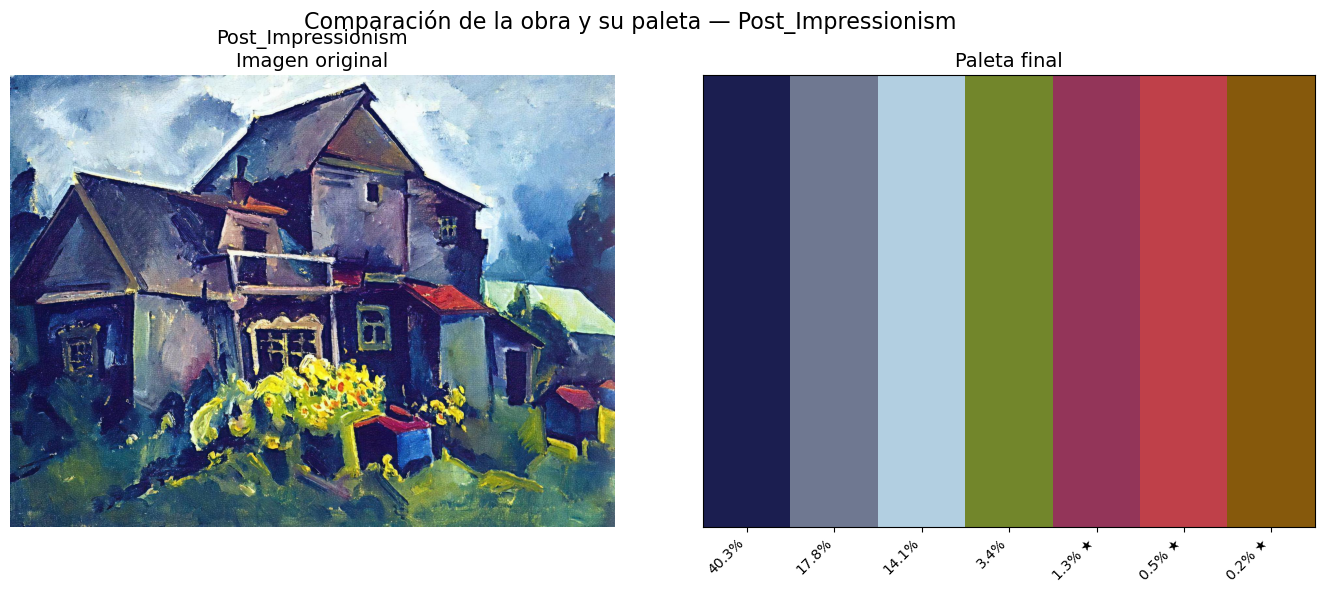

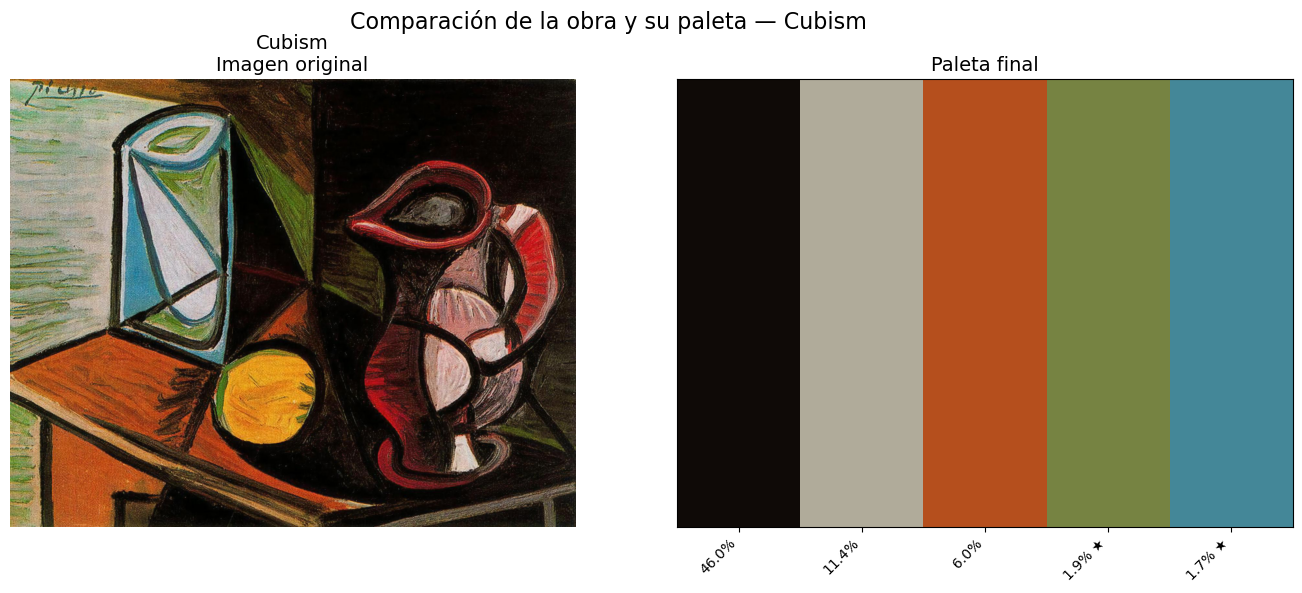

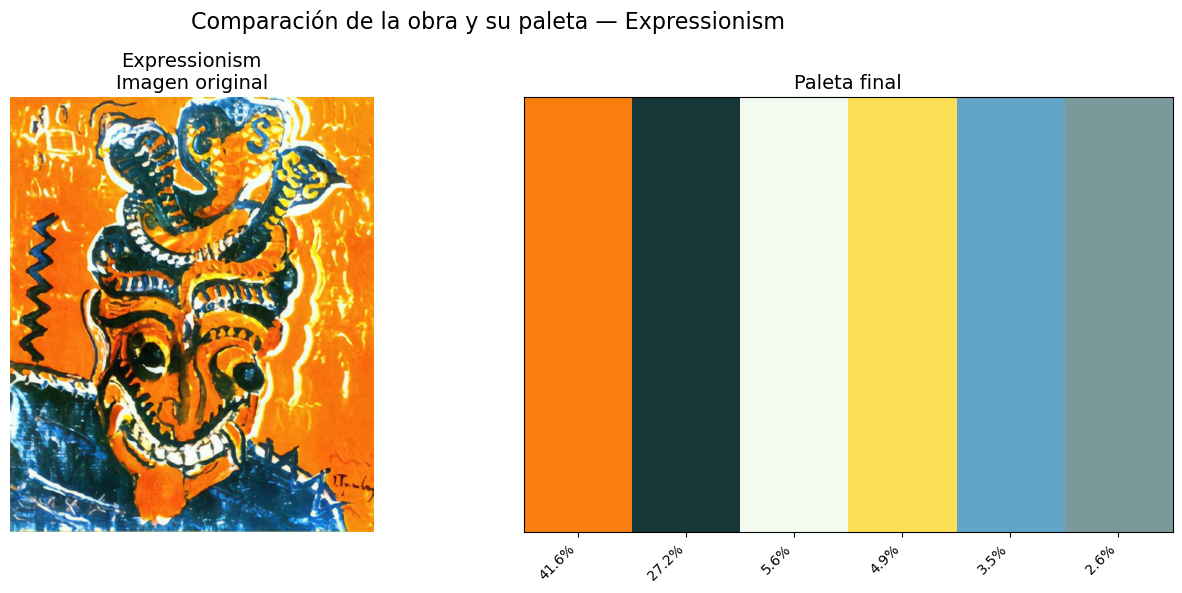

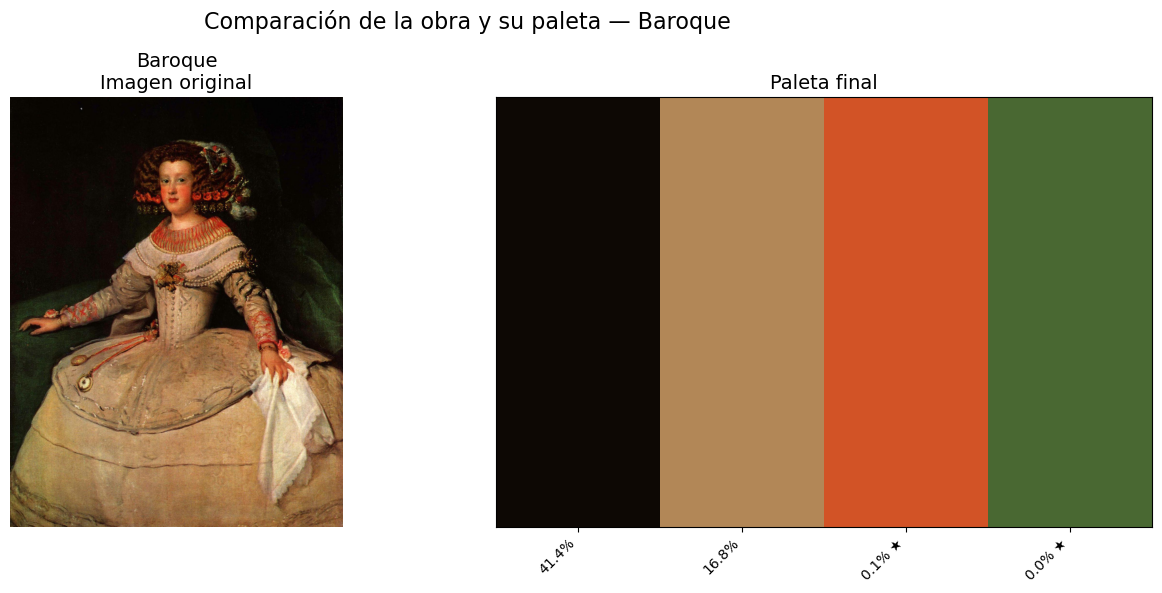

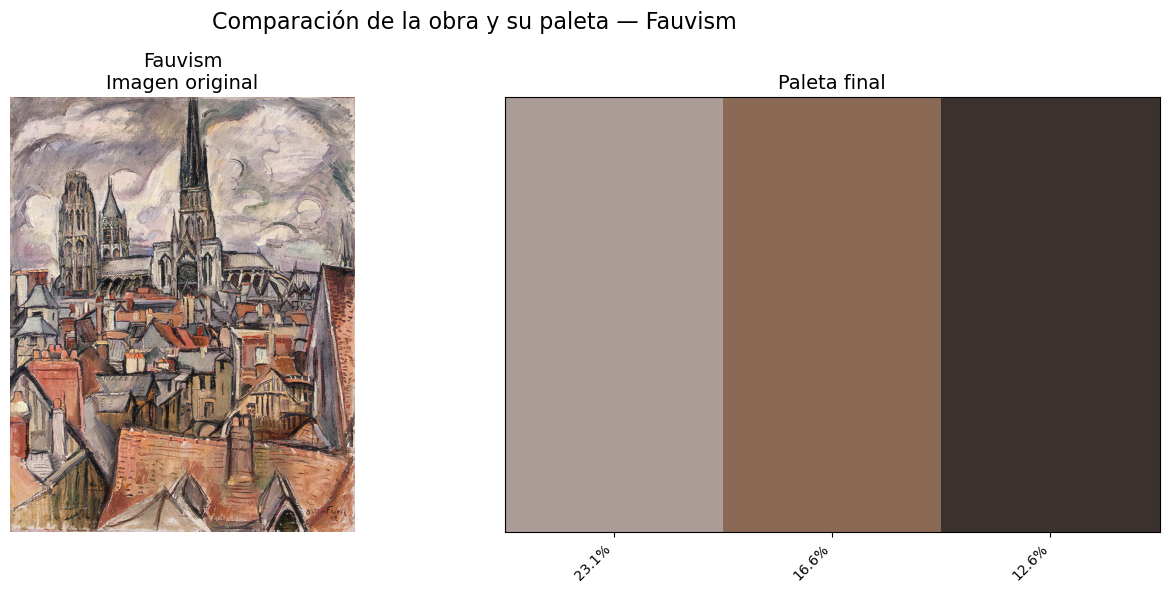

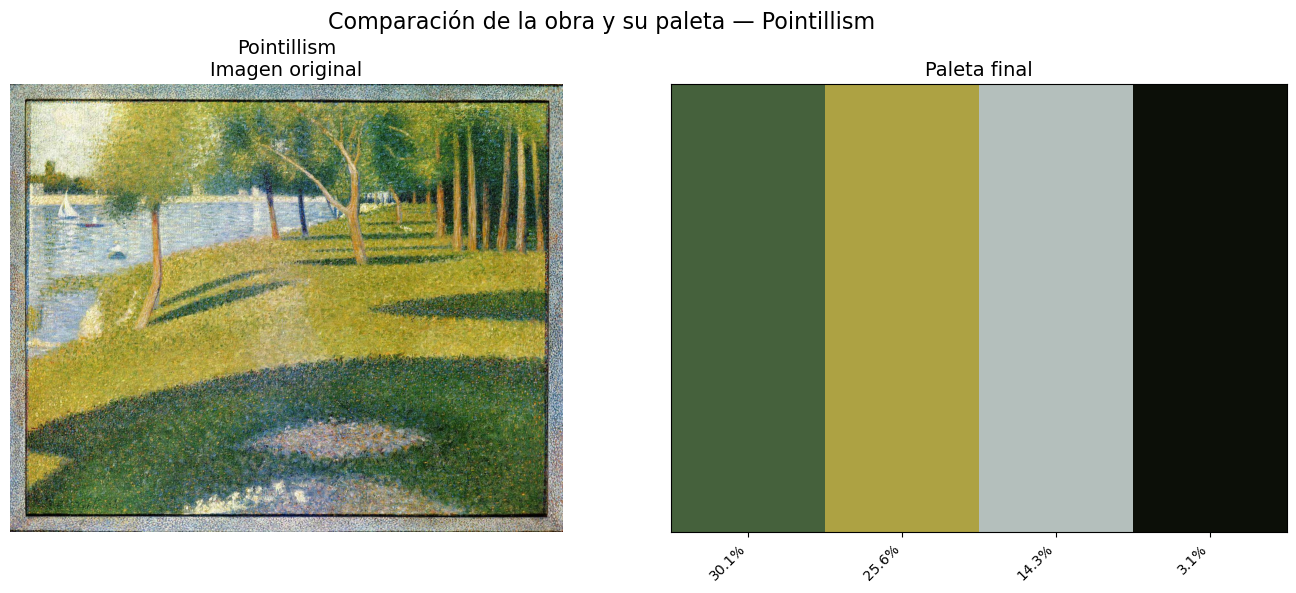

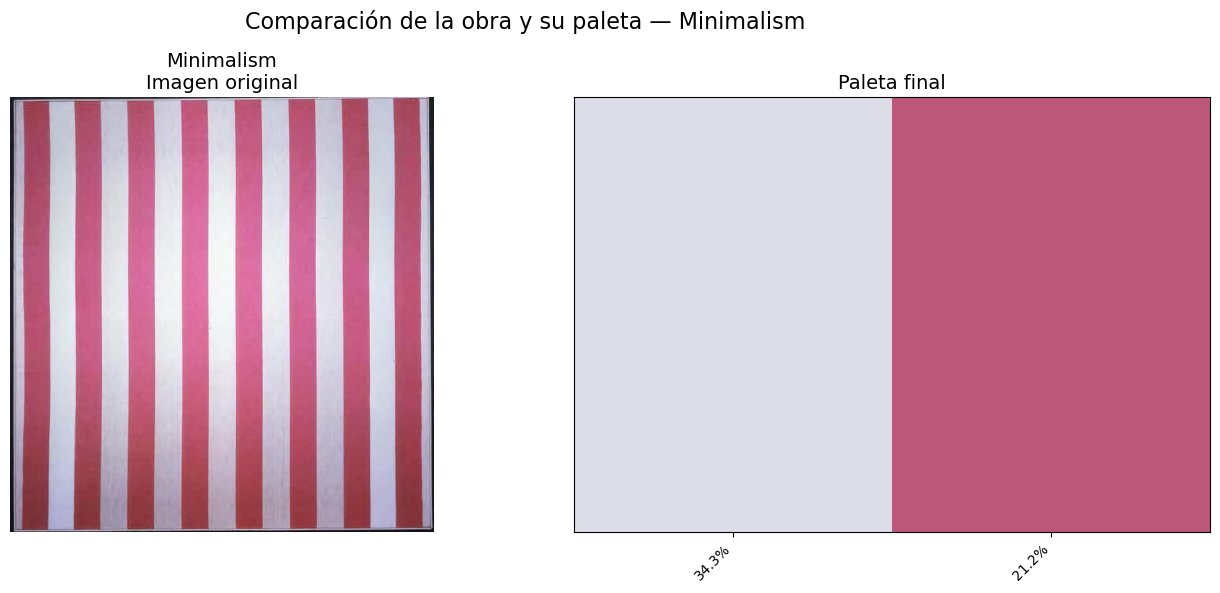

In [ ]:
# ============================================================
# COMPARACIÓN: IMAGEN ORIGINAL + PALETA FINAL
# ============================================================
# **Visualización de los colores en 2D (t-SNE)**
#
# Para observar cómo se distribuyen los colores de cada obra se añadió una
# proyección bidimensional mediante t-SNE. Cada punto corresponde a un píxel
# de una muestra aleatoria (1.500 píxeles) y se dibuja con su color RGB real.
#
# Esta vista permite apreciar visualmente la agrupación cromática de la
# pintura: colores similares aparecen cercanos entre sí, lo que ayuda a
# interpretar por qué el método identifica ciertas gamas como dominantes.

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
from sklearn.manifold import TSNE

for style, filename in selected_images.items():

    # --------------------------------------------------------
    # CARGAR IMAGEN ORIGINAL
    # --------------------------------------------------------

    image_path = os.path.join(
        path,
        style,
        filename
    )

    image = Image.open(image_path)

      # --------------------------------------------------------
    # Muestra de pixeles para t-SNE
    # --------------------------------------------------------

    prepared = preparar_imagen(image)
    pixels = np.array(prepared).reshape(-1, 3)

    np.random.seed(42)
    n_tsne = min(1500, len(pixels))

    indices = np.random.choice(
        len(pixels),
        size=n_tsne,
        replace=False
    )
    muestra = pixels[indices]

    embedding = TSNE(
        n_components=2,
        random_state=42,
        perplexity=30
    ).fit_transform(muestra)
    
    
    # --------------------------------------------------------
    # OBTENER PALETA DEL ESTILO
    # --------------------------------------------------------

    datos = df_paletas_finales[
        df_paletas_finales["Estilo"] == style
    ].copy()

    # Ordenar los colores por porcentaje
    datos = datos.sort_values(
        "Porcentaje",
        ascending=False
    )

    # --------------------------------------------------------
    # CONVERTIR COLORES RGB
    # --------------------------------------------------------

    colores = []

    for _, fila in datos.iterrows():

        rgb = (
            int(round(fila["R"])),
            int(round(fila["G"])),
            int(round(fila["B"]))
        )

        colores.append(
            np.array(rgb) / 255
        )

    # --------------------------------------------------------
    # CREAR FIGURA
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(18, 6),
        gridspec_kw={
            "width_ratios": [1.2, 1,1]
        }
    )

    # --------------------------------------------------------
    # IMAGEN ORIGINAL
    # --------------------------------------------------------

    axes[0].imshow(image)
    axes[0].set_title(
        f"{style}\nImagen original",
        fontsize=14
    )
    axes[0].axis("off")

    axes[1].scatter(
        embedding[:, 0],
        embedding[:, 1],
        c=muestra/255.0,
        s=8
    )
    axes[1].set_title(
        "Muestra de pixeles t-SNE",
        fontsize=14
    )
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    

    # --------------------------------------------------------
    # PALETA
    # --------------------------------------------------------

    if len(colores) > 0:

        palette_array = np.array(
            [colores]
        )

        axes[2].imshow(
            palette_array,
            aspect="auto"
        )

    axes[2].set_title(
        "Paleta final",
        fontsize=14
    )

    axes[2].set_xticks(
        range(len(datos))
    )

    etiquetas = []

    for _, fila in datos.iterrows():

        if fila["Selección"] == "Rescatado":
            etiqueta = (
                f"{fila['Porcentaje']:.1f}% ★"
            )
        else:
            etiqueta = (
                f"{fila['Porcentaje']:.1f}%"
            )

        etiquetas.append(etiqueta)

    axes[2].set_xticklabels(
        etiquetas,
        rotation=45,
        ha="right"
    )

    axes[2].set_yticks([])

    # --------------------------------------------------------
    # AJUSTAR Y MOSTRAR
    # --------------------------------------------------------

    plt.suptitle(
        f"Comparación de la obra y su paleta — {style}",
        fontsize=16
    )

    plt.tight_layout()

    plt.show()

Procesando: Cubism - juan-gris_still-life-with-lamp-1919.jpg
Procesando: Art_Nouveau_Modern - anna-ostroumova-lebedeva_neva-through-the-columns-of-the-exchange-1908.jpg
Procesando: Impressionism - paul-gauguin_clearing-1873.jpg
Procesando: Impressionism - frits-thaulow_evening-at-the-bay-of-frogner.jpg


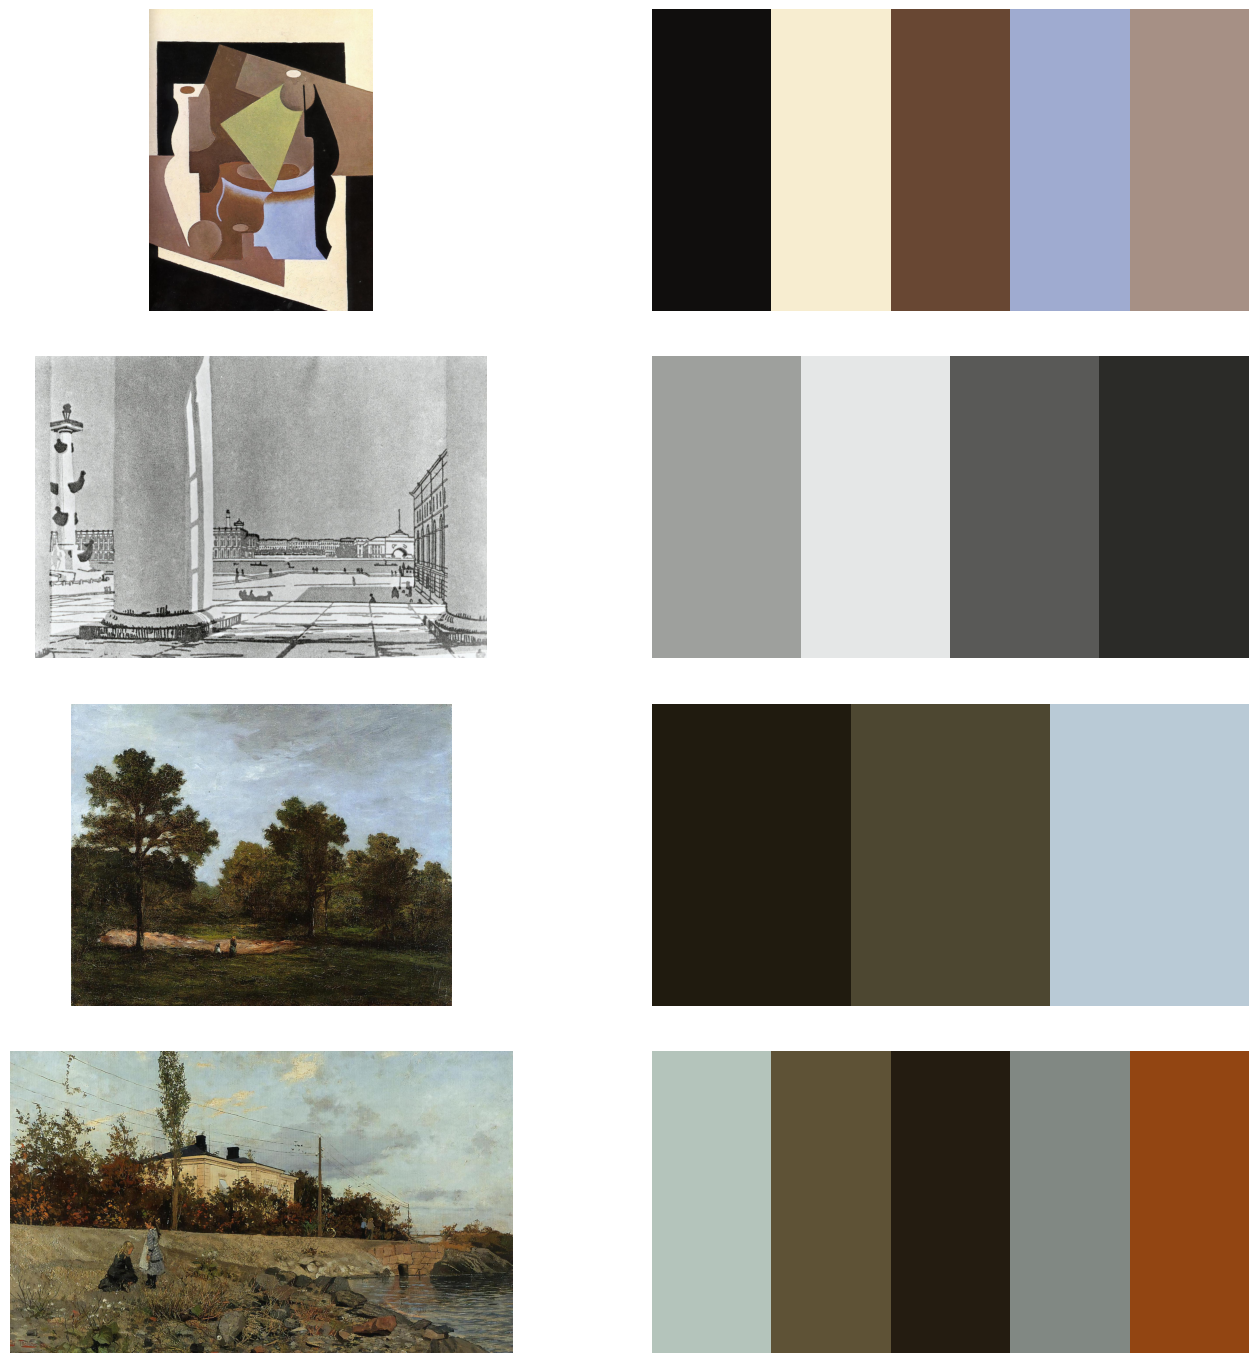

In [ ]:
# ============================================================
# 4 IMÁGENES ALEATORIAS + PALETAS FINALES
# ============================================================

import os
import random
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from sklearn.cluster import MeanShift, estimate_bandwidth
from skimage.color import rgb2lab


# ============================================================
# PARÁMETROS
# ============================================================

QUANTILE = 0.05 ##Sensibilidad Mean Shift

DELTA_E_MIN = 20

HUE_UMBRAL = 25

C_MIN = 15

PORCENTAJE_MIN = 0.10

DELTA_E_RESCATE = 30


# ============================================================
# FUNCIONES AUXILIARES
# ============================================================

def calcular_delta_e(color1_lab, color2_lab):

    return np.linalg.norm(
        np.array(color1_lab) -
        np.array(color2_lab)
    )


def calcular_hue_y_c(rgb):

    rgb_norm = np.array(
        rgb,
        dtype=float
    ) / 255.0

    lab = rgb2lab(
        rgb_norm.reshape(1, 1, 3)
    )[0, 0]

    L, a, b = lab

    c = np.sqrt(
        a**2 + b**2
    )

    hue = np.degrees(
        np.arctan2(b, a)
    ) % 360

    return hue, c, lab


def diferencia_hue(h1, h2):

    diferencia = abs(
        h1 - h2
    )

    return min(
        diferencia,
        360 - diferencia
    )


# ============================================================
# OBTENER TODAS LAS IMÁGENES DEL DATASET
# ============================================================

extensiones = (
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
)

imagenes_dataset = []

for style in os.listdir(path):

    style_path = os.path.join(
        path,
        style
    )

    if not os.path.isdir(style_path):
        continue

    for filename in os.listdir(style_path):

        if filename.lower().endswith(
            extensiones
        ):

            imagenes_dataset.append(
                (
                    style,
                    filename
                )
            )


# ============================================================
# SELECCIONAR 4 IMÁGENES ALEATORIAS
# ============================================================

random.seed(42)

imagenes_random = random.sample(
    imagenes_dataset,
    4
)


# ============================================================
# PROCESAR LAS 4 IMÁGENES
# ============================================================

resultados = []


for style, filename in imagenes_random:

    print(
        f"Procesando: {style} - {filename}"
    )

    # --------------------------------------------------------
    # CARGAR IMAGEN
    # --------------------------------------------------------

    image_path = os.path.join(
        path,
        style,
        filename
    )

    image = Image.open(
        image_path
    )

    prepared_image = preparar_imagen(
        image
    )

    pixels = np.array(
        prepared_image
    ).reshape(-1, 3)


    # --------------------------------------------------------
    # MUESTREO
    # --------------------------------------------------------

    np.random.seed(42)

    n_samples = min(
        5000,
        len(pixels)
    )

    indices = np.random.choice(
        len(pixels),
        size=n_samples,
        replace=False
    )

    sample_pixels = pixels[
        indices
    ]


    # --------------------------------------------------------
    # MEAN SHIFT
    # --------------------------------------------------------

    bandwidth = estimate_bandwidth(
        sample_pixels,
        quantile=QUANTILE,
        n_samples=n_samples
    )

    modelo_ms = MeanShift(
        bandwidth=bandwidth,
        bin_seeding=True
    )

    etiquetas = modelo_ms.fit_predict(
        sample_pixels
    )


    # --------------------------------------------------------
    # OBTENER CLUSTERS
    # --------------------------------------------------------

    clusters, counts = np.unique(
        etiquetas,
        return_counts=True
    )

    porcentajes = (
        counts /
        len(etiquetas)
    ) * 100

    orden = np.argsort(
        porcentajes
    )[::-1]


    # --------------------------------------------------------
    # CREAR CANDIDATOS
    # --------------------------------------------------------

    candidatos = []

    for posicion in orden:

        cluster = clusters[
            posicion
        ]

        porcentaje = porcentajes[
            posicion
        ]

        color = (
            modelo_ms
            .cluster_centers_[cluster]
            .astype(float)
        )

        hue, c, lab = calcular_hue_y_c(
            color
        )

        candidatos.append({

            "cluster": cluster,

            "porcentaje": porcentaje,

            "R": color[0],

            "G": color[1],

            "B": color[2],

            "Hue": hue,

            "C": c,

            "L": lab
        })


    # ========================================================
    # FILTRO ΔE
    # ========================================================

    candidatos_delta_e = []

    for candidato in candidatos:

        if len(
            candidatos_delta_e
        ) == 0:

            candidatos_delta_e.append(
                candidato
            )

            continue

        aceptar = True

        for aceptado in candidatos_delta_e:

            delta_e = calcular_delta_e(
                candidato["L"],
                aceptado["L"]
            )

            if delta_e < DELTA_E_MIN:

                aceptar = False

                break

        if aceptar:

            candidatos_delta_e.append(
                candidato
            )


    # ========================================================
    # FILTRO HUE + C*
    # ========================================================

    familias = []

    for candidato in candidatos_delta_e:

        # ----------------------------------------------------
        # COLORES NEUTROS
        # ----------------------------------------------------

        if candidato["C"] < C_MIN:

            candidato["tipo"] = "Neutro"

            familias.append(
                candidato
            )

            continue


        # ----------------------------------------------------
        # COLORES CROMÁTICOS
        # ----------------------------------------------------

        candidato["tipo"] = "Cromático"

        pertenece = False

        for familia in familias:

            if familia["tipo"] != "Cromático":
                continue

            diferencia = diferencia_hue(
                candidato["Hue"],
                familia["Hue"]
            )

            if diferencia <= HUE_UMBRAL:

                pertenece = True

                break

        if not pertenece:

            familias.append(
                candidato
            )


    # ========================================================
    # ORDENAR POR REPRESENTATIVIDAD
    # ========================================================

    familias = sorted(
        familias,
        key=lambda x: x["porcentaje"],
        reverse=True
    )


    # ========================================================
    # REGLAS DE REPRESENTATIVIDAD
    # ========================================================

    seleccionados = []

    porcentaje_acumulado_secundarios = 0

    segundo_porcentaje = None


    for candidato in familias:

        porcentaje = candidato[
            "porcentaje"
        ]


        # ----------------------------------------------------
        # PRIMER COLOR
        # ----------------------------------------------------

        if len(
            seleccionados
        ) == 0:

            seleccionados.append(
                candidato
            )

            continue


        # ----------------------------------------------------
        # SEGUNDO COLOR
        # ----------------------------------------------------

        if len(
            seleccionados
        ) == 1:

            seleccionados.append(
                candidato
            )

            segundo_porcentaje = porcentaje

            continue


        anterior = seleccionados[
            -1
        ]["porcentaje"]


        # ----------------------------------------------------
        # REGLA DEL 10 %
        # ----------------------------------------------------

        if porcentaje < (
            anterior *
            PORCENTAJE_MIN
        ):

            break


        # ----------------------------------------------------
        # REGLA ACUMULATIVA
        # ----------------------------------------------------

        if (
            porcentaje_acumulado_secundarios
            + porcentaje
        ) >= segundo_porcentaje:

            break


        seleccionados.append(
            candidato
        )

        porcentaje_acumulado_secundarios += (
            porcentaje
        )


    # ========================================================
    # RESCATE CROMÁTICO
    # ========================================================

    dominantes = seleccionados[:2]

    candidatos_rescatables = []


    for candidato in familias:

        # Ya seleccionado
        if candidato in seleccionados:
            continue

        # Solo colores cromáticos
        if candidato["tipo"] != "Cromático":
            continue


        # ----------------------------------------------------
        # ΔE CONTRA LOS DOS DOMINANTES
        # ----------------------------------------------------

        deltas = []

        for dominante in dominantes:

            delta = calcular_delta_e(
                candidato["L"],
                dominante["L"]
            )

            deltas.append(
                delta
            )


        # ----------------------------------------------------
        # CONDICIÓN DE RESCATE
        # ----------------------------------------------------

        if all(
            delta >= DELTA_E_RESCATE
            for delta in deltas
        ):

            candidato_rescatable = (
                candidato.copy()
            )

            candidato_rescatable[
                "delta_e_dominantes"
            ] = min(deltas)

            candidatos_rescatables.append(
                candidato_rescatable
            )


    # ========================================================
    # INCORPORAR TODOS LOS RESCATABLES
    # ========================================================

    candidatos_rescatables = sorted(
        candidatos_rescatables,
        key=lambda x:
            x["delta_e_dominantes"],
        reverse=True
    )

    rescates = (
        candidatos_rescatables.copy()
    )


    # ========================================================
    # PALETA FINAL
    # ========================================================

    paleta_final = []

    for candidato in seleccionados:

        paleta_final.append(
            (
                candidato["R"],
                candidato["G"],
                candidato["B"]
            )
        )


    for candidato in rescates:

        paleta_final.append(
            (
                candidato["R"],
                candidato["G"],
                candidato["B"]
            )
        )


    resultados.append({

        "style": style,

        "filename": filename,

        "image": image,

        "palette": paleta_final

    })


# ============================================================
# VISUALIZACIÓN
# ============================================================

fig, axes = plt.subplots(
    4,
    2,
    figsize=(14, 14),
    gridspec_kw={
        "width_ratios": [1.2, 1]
    }
)


for i, resultado in enumerate(
    resultados
):

    image = resultado[
        "image"
    ]

    palette = resultado[
        "palette"
    ]


    # --------------------------------------------------------
    # IMAGEN ORIGINAL
    # --------------------------------------------------------

    axes[i, 0].imshow(
        image
    )

    axes[i, 0].axis(
        "off"
    )


    # --------------------------------------------------------
    # PALETA
    # --------------------------------------------------------

    colores = np.array(
        palette,
        dtype=float
    ) / 255.0

    colores = colores.reshape(
        1,
        len(palette),
        3
    )

    axes[i, 1].imshow(
        colores,
        aspect="auto"
    )

    axes[i, 1].axis(
        "off"
    )


# ============================================================
# AJUSTAR ESPACIADO
# ============================================================

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.98,
    bottom=0.02,
    wspace=0.05,
    hspace=0.15
)

plt.show()

In [1]:
plt.savefig(
    "mapa_conceptual_pipeline_final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'plt' is not defined